In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pickle
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv(r"C:\Users\LENOVO\Downloads\Social_Media_Mental_Wellbeing.csv")
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Social_Support_Score,Cyberbullying_Exposure,Social_Comparison_Level,Exercise_Days_Per_Week,Stress_Level,Mental_Health_Score
0,29,Female,United Kingdom,Undergraduate,Facebook,Entertainment,3.59,90,3.04,1.34,7.19,5.4,No,4,3,Medium,93.0
1,30,Non-binary,India,Undergraduate,TikTok,Communication,1.92,26,3.04,1.96,6.48,4.9,No,3,4,Medium,73.8
2,27,Male,India,Undergraduate,YouTube,Networking,2.20,77,1.35,1.17,7.89,5.7,No,3,1,Medium,86.6
3,27,Male,India,Undergraduate,Other,Mixed,2.99,48,4.72,1.15,4.61,6.9,No,2,5,Medium,96.7
4,29,Female,Australia,Postgraduate,Instagram,Entertainment,5.01,85,1.41,0.37,7.14,8.2,No,5,0,Medium,80.5


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      50000 non-null  int64  
 1   Gender                   50000 non-null  object 
 2   Country                  50000 non-null  object 
 3   Academic_Level           50000 non-null  object 
 4   Most_Used_Platform       50000 non-null  object 
 5   Purpose_Of_Use           50000 non-null  object 
 6   Avg_Daily_Usage_Hours    50000 non-null  float64
 7   Daily_Unlocks            50000 non-null  int64  
 8   Study_Hours              50000 non-null  float64
 9   Physical_Activity_Hours  50000 non-null  float64
 10  Sleep_Hours_Per_Night    50000 non-null  float64
 11  Social_Support_Score     50000 non-null  float64
 12  Cyberbullying_Exposure   50000 non-null  object 
 13  Social_Comparison_Level  50000 non-null  int64  
 14  Exercise_Days_Per_Week

In [4]:
df.isna().sum()

Age                        0
Gender                     0
Country                    0
Academic_Level             0
Most_Used_Platform         0
Purpose_Of_Use             0
Avg_Daily_Usage_Hours      0
Daily_Unlocks              0
Study_Hours                0
Physical_Activity_Hours    0
Sleep_Hours_Per_Night      0
Social_Support_Score       0
Cyberbullying_Exposure     0
Social_Comparison_Level    0
Exercise_Days_Per_Week     0
Stress_Level               0
Mental_Health_Score        0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

### EDA

##### Target Variable Analysis

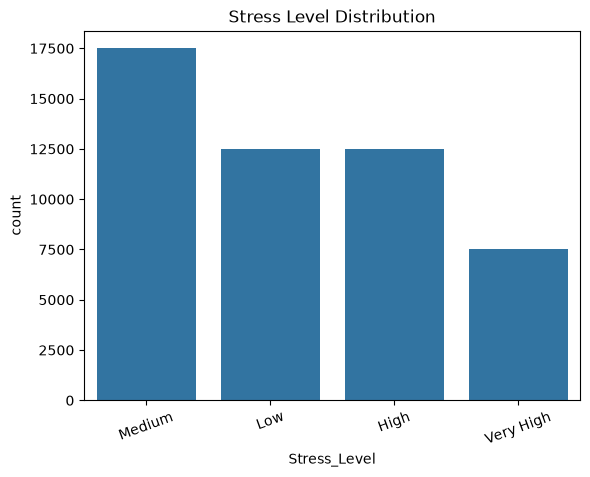

In [6]:
sns.countplot(x="Stress_Level", data=df, order=df["Stress_Level"].value_counts().index)
plt.title("Stress Level Distribution")
plt.xticks(rotation=20)
plt.show()

##### Sleep Hours by Stress Level

##### Numerical Feature Distributions

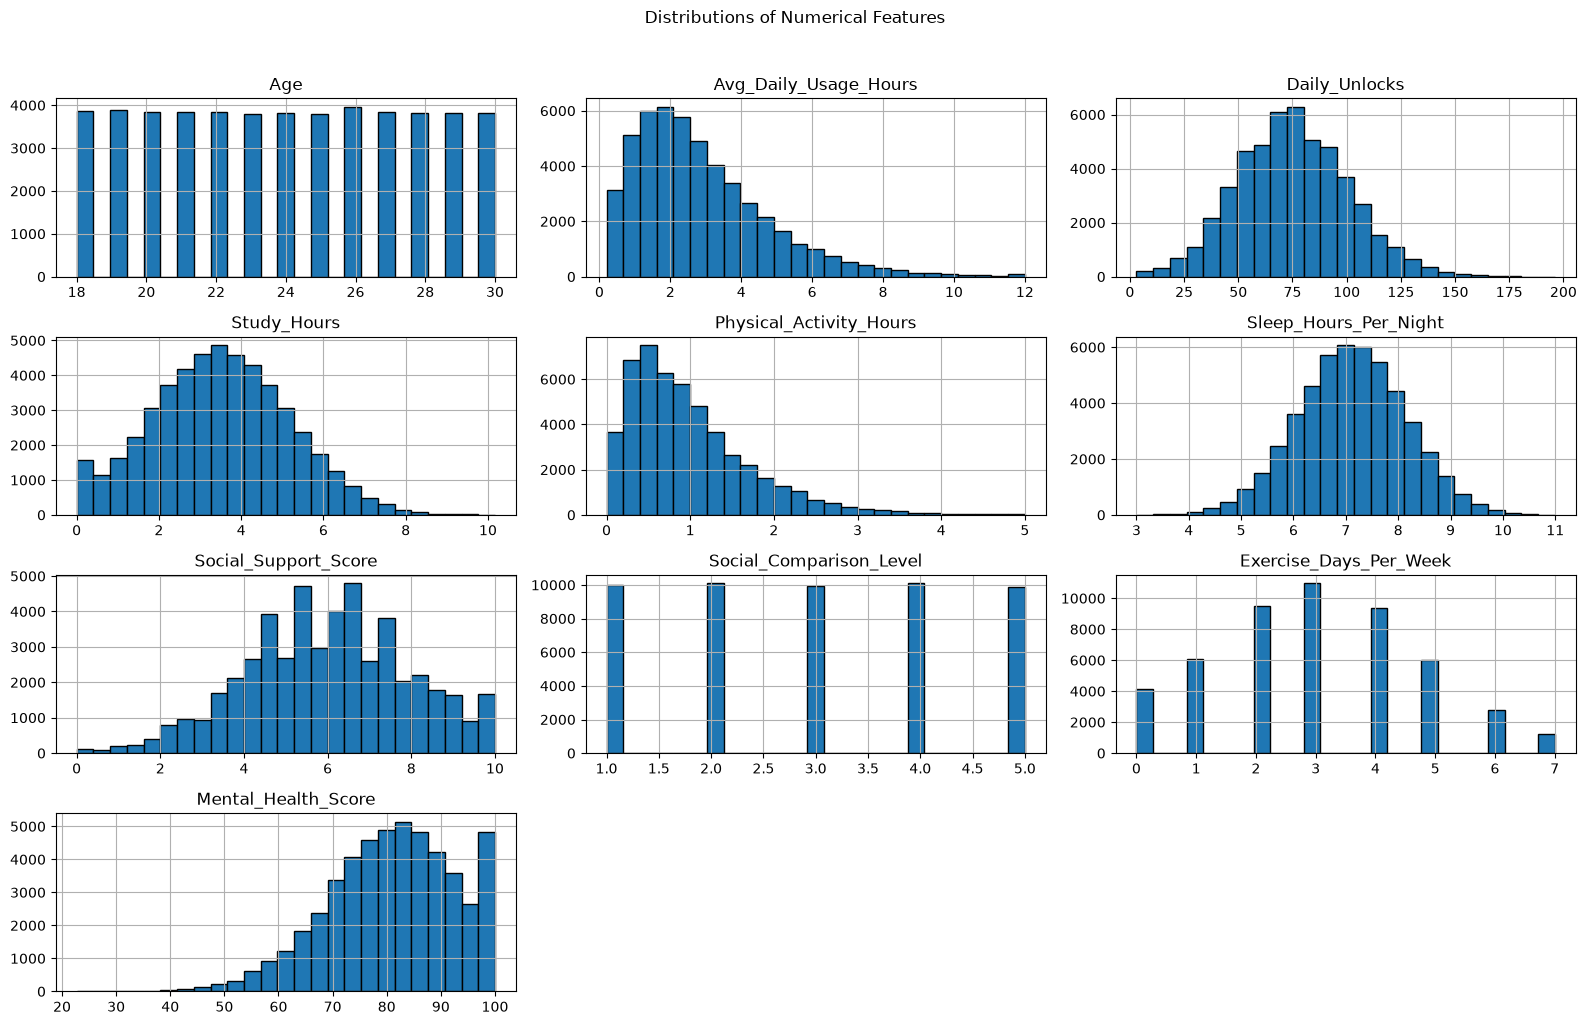

In [7]:
numeric_eda_cols = [
    "Age", "Avg_Daily_Usage_Hours", "Daily_Unlocks", "Study_Hours",
    "Physical_Activity_Hours", "Sleep_Hours_Per_Night",
    "Social_Support_Score", "Social_Comparison_Level", "Exercise_Days_Per_Week",
    "Mental_Health_Score"
]
df[numeric_eda_cols].hist(figsize=(16, 10), bins=25, edgecolor="black")
plt.suptitle("Distributions of Numerical Features", y=1.02)
plt.tight_layout()
plt.show()

##### Stress Level by Academic Level and Platform

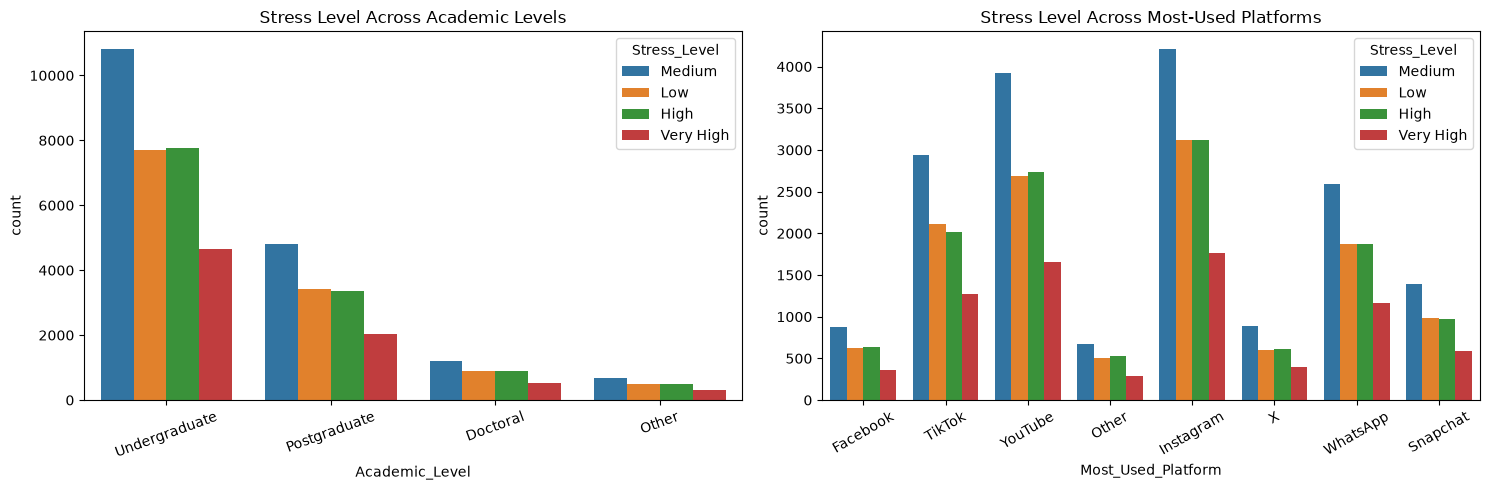

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(data=df, x="Academic_Level", hue="Stress_Level", ax=axes[0])
axes[0].set_title("Stress Level Across Academic Levels")
axes[0].tick_params(axis="x", rotation=20)
sns.countplot(data=df, x="Most_Used_Platform", hue="Stress_Level", ax=axes[1])
axes[1].set_title("Stress Level Across Most-Used Platforms")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

##### Social Media Usage and Mental Health Score

##### Correlation Heatmap

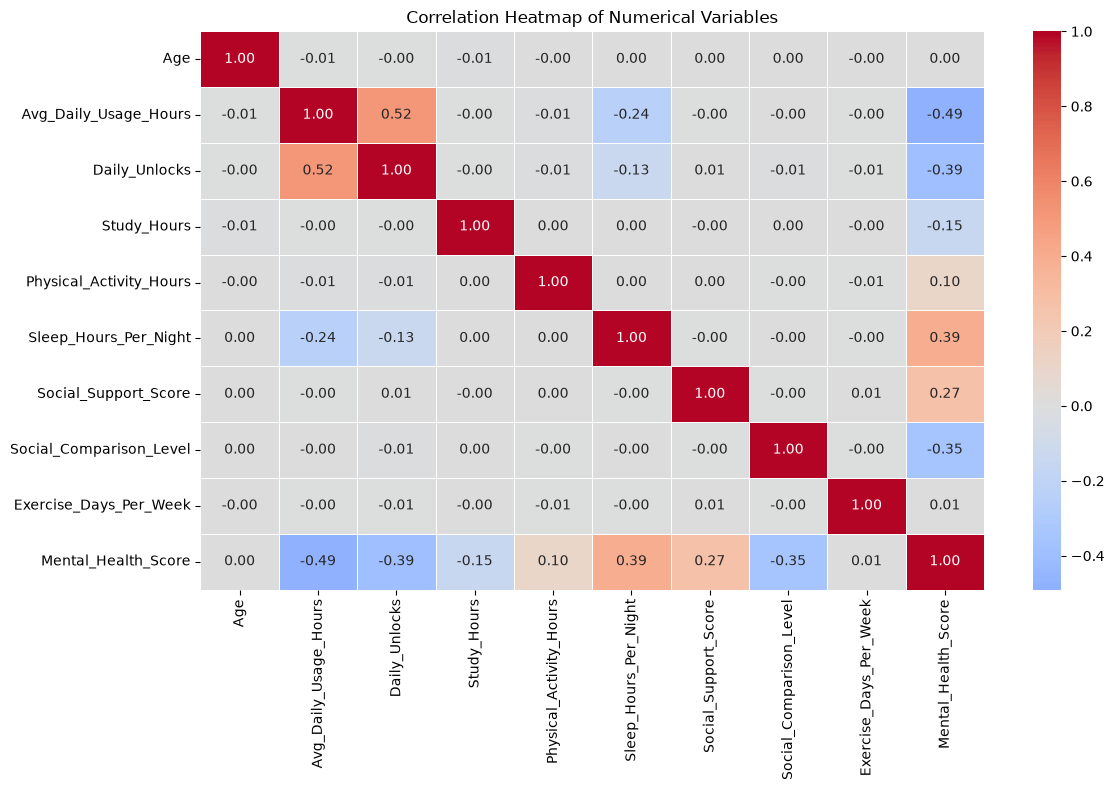

In [9]:
plt.figure(figsize=(12, 8))
corr = df.select_dtypes(include=np.number).corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", linewidths=0.4)
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

##### Cyberbullying Exposure and Stress Level

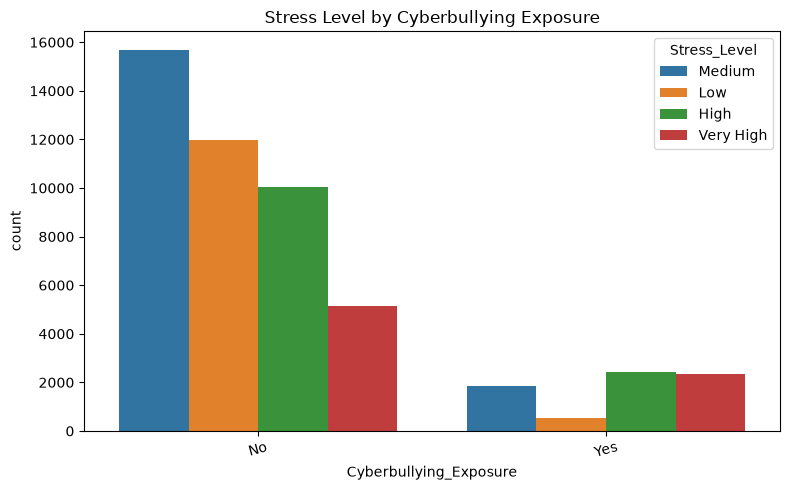

In [10]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Cyberbullying_Exposure", hue="Stress_Level")
plt.title("Stress Level by Cyberbullying Exposure")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Data Preprocessing

`Academic_Level` is treated as a categorical **ordinal** feature and encoded in education-level order. Nominal categories are one-hot encoded, while already-numeric scores/counts remain in the numerical pipeline. Verify the exact labels with `df["Academic_Level"].unique()` and adjust the ordinal order if needed.

In [11]:
x = df.drop(["Stress_Level"], axis=1)
y = df["Stress_Level"]

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    x, y, train_size=0.8, random_state=23, stratify=y
)

In [12]:
nominal_cols = [
    "Gender", "Country", "Most_Used_Platform",
    "Purpose_Of_Use", "Cyberbullying_Exposure"
]
ordinal_cols = ["Academic_Level"]
numerical_cols = [
    "Age", "Avg_Daily_Usage_Hours", "Daily_Unlocks", "Study_Hours",
    "Physical_Activity_Hours", "Sleep_Hours_Per_Night",
    "Social_Support_Score", "Social_Comparison_Level", "Exercise_Days_Per_Week"
]

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import RFE
from sklearn.tree import DecisionTreeClassifier

In [14]:
nominal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [15]:
nominal_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('encoder', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto ac

In [16]:
academic_level_order = ["High School", "Undergraduate", "Graduate", "Postgraduate"]
ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=[academic_level_order],
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

In [17]:
ordinal_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('encoder', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto ac

In [18]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [19]:
numerical_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account fo

In [20]:
Data_preprocessing = ColumnTransformer([
    ("nominal", nominal_pipeline, nominal_cols),
    ("ordinal", ordinal_pipeline, ordinal_cols),
    ("numerical", numerical_pipeline, numerical_cols)
])


In [21]:
Data_preprocessing

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('nominal', ...), ('ordinal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``f

In [22]:
def make_rfe():
    return RFE(
        estimator=DecisionTreeClassifier(max_depth=5, random_state=23),
        n_features_to_select=0.5,
        step=0.2
    )

### Model Building

### Logistic Regression

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, f1_score,precision_score,recall_score

logistic_model = Pipeline([
    ("preprocessing", Data_preprocessing),
    ("rfe", make_rfe()),
    ("Algorithm", LogisticRegression(max_iter=1500, class_weight="balanced"))
])
logistic_model.fit(x_train, y_train)
y_pred = logistic_model.predict(x_test)
print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("Test precision:", precision_score(y_test, y_pred,average='macro'))
print("Test recall:", recall_score(y_test, y_pred,average='macro'))
print("Test f1:", f1_score(y_test, y_pred,average='macro'))
print(classification_report(y_test, y_pred, zero_division=0))

Test Accuracy: 0.625
Test precision: 0.6266429773482858
Test recall: 0.6506285714285714
Test f1: 0.6359910082122464
              precision    recall  f1-score   support

        High       0.53      0.53      0.53      2500
         Low       0.69      0.78      0.73      2500
      Medium       0.62      0.52      0.56      3500
   Very High       0.67      0.77      0.72      1500

    accuracy                           0.62     10000
   macro avg       0.63      0.65      0.64     10000
weighted avg       0.62      0.62      0.62     10000



In [24]:
x_training = logistic_model.predict(x_train)
x_testing = logistic_model.predict(x_test)

train_acc = accuracy_score(y_train,x_training)
test_acc = accuracy_score(y_test,x_testing)

print("Train acc Score:",train_acc)
print("Test acc Score:",test_acc)

Train acc Score: 0.622575
Test acc Score: 0.625


### Decision Tree

In [25]:
from sklearn.tree import DecisionTreeClassifier
dt_model = Pipeline([
    ("preprocessing", Data_preprocessing),
    ("rfe", make_rfe()),
    ("dt", DecisionTreeClassifier(class_weight="balanced", random_state=23))
])
dt_model.fit(x_train, y_train)
y_pred = dt_model.predict(x_test)
print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("Test precision:", precision_score(y_test, y_pred,average='macro'))
print("Test recall:", recall_score(y_test, y_pred,average='macro'))
print("Test f1:", f1_score(y_test, y_pred,average='macro'))
print(classification_report(y_test, y_pred, zero_division=0))

Test Accuracy: 0.502
Test precision: 0.5126769528111873
Test recall: 0.511552380952381
Test f1: 0.5121086294590413
              precision    recall  f1-score   support

        High       0.40      0.40      0.40      2500
         Low       0.59      0.59      0.59      2500
      Medium       0.48      0.48      0.48      3500
   Very High       0.58      0.57      0.58      1500

    accuracy                           0.50     10000
   macro avg       0.51      0.51      0.51     10000
weighted avg       0.50      0.50      0.50     10000



In [26]:
x_training = dt_model.predict(x_train)
x_testing = dt_model.predict(x_test)

train_acc = accuracy_score(y_train,x_training)
test_acc = accuracy_score(y_test,x_testing)

print("Train acc Score:",train_acc)
print("Test acc Score:",test_acc)

Train acc Score: 1.0
Test acc Score: 0.502


### Random forest

In [27]:
from sklearn.ensemble import RandomForestClassifier
rf_model = Pipeline([
    ("preprocessing", Data_preprocessing),
    ("rfe", make_rfe()),
    ("rf", RandomForestClassifier(
        n_estimators=150, min_samples_leaf=2,
        class_weight="balanced_subsample", random_state=23, n_jobs=-1
    ))
])
rf_model.fit(x_train, y_train)
y_pred = rf_model.predict(x_test)
print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("Test precision:", precision_score(y_test, y_pred,average='macro'))
print("Test recall:", recall_score(y_test, y_pred,average='macro'))
print("Test f1:", f1_score(y_test, y_pred,average='macro'))
print(classification_report(y_test, y_pred, zero_division=0))

Test Accuracy: 0.6127
Test precision: 0.6312609247790716
Test recall: 0.6160238095238095
Test f1: 0.6228971163971126
              precision    recall  f1-score   support

        High       0.51      0.52      0.52      2500
         Low       0.72      0.69      0.71      2500
      Medium       0.57      0.61      0.59      3500
   Very High       0.72      0.64      0.68      1500

    accuracy                           0.61     10000
   macro avg       0.63      0.62      0.62     10000
weighted avg       0.62      0.61      0.61     10000



In [28]:
x_training = rf_model.predict(x_train)
x_testing = rf_model.predict(x_test)

train_acc = accuracy_score(y_train,x_training)
test_acc = accuracy_score(y_test,x_testing)

print("Train accuracy Score:",train_acc)
print("Test accuracy Score:",test_acc)

Train accuracy Score: 0.992325
Test accuracy Score: 0.6127


### KNN

In [29]:
from sklearn.neighbors import KNeighborsClassifier
knn_model = Pipeline([
    ("preprocessing", Data_preprocessing),
    ("rfe", make_rfe()),
    ("knn", KNeighborsClassifier(n_neighbors=7))
])
knn_model.fit(x_train, y_train)
y_pred = knn_model.predict(x_test)
print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("Test precision:", precision_score(y_test, y_pred,average='macro'))
print("Test recall:", recall_score(y_test, y_pred,average='macro'))
print("Test f1:", f1_score(y_test, y_pred,average='macro'))

Test Accuracy: 0.5458
Test precision: 0.5801465527295916
Test recall: 0.5418666666666666
Test f1: 0.5543597625571484


In [30]:
x_training = knn_model.predict(x_train)
x_testing = knn_model.predict(x_test)

train_acc = accuracy_score(y_train,x_training)
test_acc = accuracy_score(y_test,x_testing)

print("Train accuracy Score:",train_acc)
print("Test accuracy Score:",test_acc)

Train accuracy Score: 0.674175
Test accuracy Score: 0.5458


### SVC

In [31]:
from sklearn.svm import SVC
svc_model = Pipeline([
    ("preprocessing", Data_preprocessing),
    ("rfe", make_rfe()),
    ("svc", SVC(class_weight="balanced"))
])
svc_model.fit(x_train, y_train)
y_pred = svc_model.predict(x_test)
print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("Test precision:", precision_score(y_test, y_pred,average='macro'))
print("Test recall:", recall_score(y_test, y_pred,average='macro'))
print("Test f1:", f1_score(y_test, y_pred,average='macro'))

Test Accuracy: 0.6202
Test precision: 0.6268003713604611
Test recall: 0.6417238095238095
Test f1: 0.632570669130847


In [33]:
x_training = svc_model.predict(x_train)
x_testing = svc_model.predict(x_test)

train_acc = accuracy_score(y_train,x_training)
test_acc = accuracy_score(y_test,x_testing)

print("Train acc Score:",train_acc)
print("Test acc Score:",test_acc)

Train acc Score: 0.651
Test acc Score: 0.6202


#### XGBoost

In [35]:
from xgboost import XGBClassifier

In [39]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

In [41]:
xgb_model = Pipeline([
    ("Preprocessing", Data_preprocessing),
    ("rfe", make_rfe()),
    ("Algorithm", XGBClassifier())
])

xgb_model.fit(x_train, y_train_encoded)

y_pred = xgb_model.predict(x_test)

print("Accuracy :", accuracy_score(y_test_encoded, y_pred))
print("Test precision:", precision_score(y_test_encoded, y_pred,average='macro'))
print("Test recall:", recall_score(y_test_encoded, y_pred,average='macro'))
print("Test f1:", f1_score(y_test_encoded, y_pred,average='macro'))



Accuracy : 0.6152
Test precision: 0.6373234951819077
Test recall: 0.6151714285714286
Test f1: 0.6247043626653314


In [43]:
x_training = xgb_model.predict(x_train)
x_testing = xgb_model.predict(x_test)

train_acc = accuracy_score(y_train_encoded,x_training)
test_acc = accuracy_score(y_test_encoded,x_testing)

print("Train acc Score:",train_acc)
print("Test acc Score:",test_acc)

Train acc Score: 0.776675
Test acc Score: 0.6152


### Cross Validation

In [34]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=23)
cv_scores = cross_val_score(
    logistic_model, x_train, y_train, scoring="accuracy", cv=skf, n_jobs=-1
)
print("5-Fold CV Accuracy Scores:", cv_scores)
print("Mean CV Accuracy:", cv_scores.mean())

5-Fold CV Accuracy Scores: [0.61825  0.62875  0.620625 0.618    0.619625]
Mean CV Accuracy: 0.62105


### HyperparameterTuning

In [39]:
from sklearn.model_selection import RandomizedSearchCV

search_space = {
    "Algorithm__C": [0.01, 0.1, 1, 10, 100],
    "Algorithm__solver": ["lbfgs"],
    "Algorithm__max_iter": [500, 1000, 1500]
}

rsv = RandomizedSearchCV(
    estimator=logistic_model,
    param_distributions=search_space,
    n_iter=5,
    cv=skf,
    scoring="accuracy",
    random_state=23,
    n_jobs=-1
)

rsv.fit(x_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1500))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'Algorithm__C': [0.01, 0.1, ...], 'Algorithm__max_iter': [500, 1000, ...], 'Algorithm__solver': ['lbfgs']}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",23
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Al

In [40]:
print("Best Parameters:", rsv.best_params_)
print("Best CV Accuracy:", rsv.best_score_)

Best Parameters: {'Algorithm__solver': 'lbfgs', 'Algorithm__max_iter': 1500, 'Algorithm__C': 10}
Best CV Accuracy: 0.6213


### Final Model

In [41]:
from sklearn.metrics import accuracy_score, classification_report

final_model = rsv.best_estimator_

y_pred = final_model.predict(x_test)

print("Logistic Regression Test Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Logistic Regression Test Accuracy: 0.6253
              precision    recall  f1-score   support

        High       0.53      0.53      0.53      2500
         Low       0.69      0.78      0.73      2500
      Medium       0.62      0.52      0.56      3500
   Very High       0.67      0.77      0.72      1500

    accuracy                           0.63     10000
   macro avg       0.63      0.65      0.64     10000
weighted avg       0.62      0.63      0.62     10000



In [43]:
final_model.fit(x, y)
with open(r"C:\Users\LENOVO\Desktop\streamlit\Social media and mental well being\classification.pkl", "wb") as f:
    pickle.dump(final_model, f)
print("Classification model saved successfully")

Classification model saved successfully
